# Evaluación del Clasificador de Sentadillas con MediaPipe

Este cuaderno mide qué tan bien el **clasificador de forma** de sentadillas (en `squat_analysis_api`) distingue entre sentadillas con **buena forma** y **mala forma**, usando el conjunto etiquetado en la carpeta `eval/`.

**Datos:** `eval/Good/` (20 videos) y `eval/Bad/` (20 videos). Cada video tiene una etiqueta real a nivel de video.

**Cómo funciona:** se ejecuta el analizador cuadro por cuadro sobre cada video; cada repetición recibe un veredicto (`correcta`/`incorrecta`) y luego esos veredictos se combinan en una sola predicción por video.

**Clase positiva = `malo`** — detectar la mala forma es el objetivo relevante de seguridad, así que la *sensibilidad* sobre la clase `malo` es la cifra más importante.

**Se evalúan los dos modos:**
- **Principiante** (`beginner`): umbrales más permisivos.
- **Profesional** (`pro`): umbrales más estrictos (exige más profundidad, menos avance de rodilla, menos inclinación del torso).

**Reglas de agregación** (cómo se combinan los veredictos de cada repetición en un veredicto por video):
- `majority` (mayoría): el video es `malo` solo si la mayoría de las repeticiones están marcadas.
- `all` (estricta): una sola repetición marcada condena todo el video.

## 1. Configuración e importaciones

In [1]:
import sys, time, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# El cuaderno vive en <repo>/eval/ ; el paquete del analizador y el script
# evaluate_dataset estan en <repo>/squat_analysis_api/.
EVAL_ROOT = Path.cwd() if Path.cwd().name == "eval" else Path.cwd() / "eval"
REPO_ROOT = EVAL_ROOT.parent
API_DIR = REPO_ROOT / "squat_analysis_api"
sys.path.insert(0, str(API_DIR))  # para poder importar evaluate_dataset (script de nivel superior)

import evaluate_dataset as ed
from squat_analysis_api.utils import get_mediapipe_pose

POSITIVO, NEGATIVO = "bad", "good"      # clase positiva = mala forma
MODES = ["beginner", "pro"]
RULES = ["majority", "all"]
REGLA_PRINCIPAL = "majority"

# Nombres en espanol para titulos y tablas.
MODO_ES = {"beginner": "Principiante", "pro": "Profesional"}
REGLA_ES = {"majority": "mayoria", "all": "estricta"}

print(f"carpeta eval  : {EVAL_ROOT}")
print(f"videos Good   : {len(list((EVAL_ROOT / 'Good').glob('*.mp4')))}")
print(f"videos Bad    : {len(list((EVAL_ROOT / 'Bad').glob('*.mp4')))}")

carpeta eval  : /Users/dele/Documents/Projects/Willie_TP/eval
videos Good   : 20
videos Bad    : 20


## 2. Ejecución del analizador sobre todos los videos

Para cada **modo** y cada **video** se ejecuta el analizador una sola vez y se registran: total de repeticiones, repeticiones correctas/incorrectas, las etiquetas de fallo detectadas y el tiempo de procesamiento. La predicción por video se calcula para **ambas reglas** de agregación. Los nombres de carpeta `Good`/`Bad` se normalizan a `good`/`bad` para coincidir con la convención del analizador.

In [2]:
def recolectar(mode: str) -> pd.DataFrame:
    """Ejecuta el analizador sobre todo el conjunto eval en una sola sesion de MediaPipe."""
    filas = []
    clases = ed.discover_dataset(EVAL_ROOT)  # {'Bad': [...], 'Good': [...]}
    with get_mediapipe_pose() as pose:
        for carpeta, videos in clases.items():
            etiqueta = carpeta.lower()  # 'Good' -> 'good', 'Bad' -> 'bad'
            for video in videos:
                t0 = time.perf_counter()
                total, correctas, incorrectas, fallos = ed.analyze_video(video, pose, mode)
                segundos = time.perf_counter() - t0
                fila = {
                    "archivo": video.name,
                    "etiqueta": etiqueta,
                    "modo": mode,
                    "reps_total": total,
                    "reps_correctas": correctas,
                    "reps_incorrectas": incorrectas,
                    "fallos": sorted(set(fallos)),
                    "segundos": round(segundos, 2),
                }
                for regla in RULES:
                    fila[f"pred_{regla}"] = ed.predict_label(correctas, incorrectas, regla)
                filas.append(fila)
                print(f"  [{mode:<10}][{etiqueta:>4}] {video.name:<14} "
                      f"reps={total:<2} ok={correctas:<2} mal={incorrectas:<2} "
                      f"-> may={fila['pred_majority']:<5} est={fila['pred_all']:<5} ({segundos:4.1f}s)", flush=True)
    return pd.DataFrame(filas)

frames = {}
for m in MODES:
    print(f"\n=== modo={MODO_ES[m]} ({m}) ===")
    frames[m] = recolectar(m)

df = pd.concat(frames.values(), ignore_index=True)
print(f"\nFilas totales: {len(df)}  ({df['archivo'].nunique()} videos x {len(MODES)} modos)")


=== modo=Principiante (beginner) ===


I0000 00:00:1781020576.669052 3066145 gl_context.cc:357] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M4
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1781020576.736891 3066251 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1781020576.743533 3066252 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/Users/dele/Documents/Projects/Willie_TP/squat_analysis_api/.venv/lib/python3.12/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


  [beginner  ][ bad] BAD001.mp4     reps=1  ok=0  mal=1  -> may=bad   est=bad   ( 2.6s)


  [beginner  ][ bad] BAD002.mp4     reps=1  ok=0  mal=1  -> may=bad   est=bad   ( 3.4s)


  [beginner  ][ bad] BAD003.mp4     reps=1  ok=0  mal=1  -> may=bad   est=bad   ( 3.7s)


  [beginner  ][ bad] BAD004.mp4     reps=1  ok=0  mal=1  -> may=bad   est=bad   ( 3.1s)


... (75 outputs left out)

  [pro       ][good] GOOD018.mp4    reps=1  ok=1  mal=0  -> may=good  est=good  ( 3.3s)


  [pro       ][good] GOOD019.mp4    reps=1  ok=1  mal=0  -> may=good  est=good  ( 3.3s)


  [pro       ][good] GOOD020.mp4    reps=1  ok=1  mal=0  -> may=good  est=good  ( 2.7s)



Filas totales: 80  (40 videos x 2 modos)


## 3. Qué significa cada métrica

Todas las métricas usan **`malo` como clase positiva** (lo que queremos detectar). Primero, los cuatro resultados posibles que componen la **matriz de confusión**:

| Sigla | Nombre | Significado |
|---|---|---|
| **VP** | Verdadero Positivo | sentadilla **mala** correctamente marcada como mala |
| **FP** | Falso Positivo | sentadilla **buena** marcada como mala (falsa alarma) |
| **VN** | Verdadero Negativo | sentadilla **buena** correctamente dejada pasar |
| **FN** | Falso Negativo | sentadilla **mala** que pasó como buena (el error peligroso) |

Y las métricas que se derivan de ellos:

- **Exactitud (Accuracy):** porcentaje de **todos** los videos clasificados correctamente (buenos y malos juntos). Fácil de leer, pero engaña si las clases están desbalanceadas.
- **Precisión (Precision):** de todos los videos que el sistema marcó como malos, qué fracción **realmente** lo era. Mide las falsas alarmas: precisión baja = molesta a usuarios con buena forma.
- **Sensibilidad / Exhaustividad (Recall):** de todas las sentadillas **realmente** malas, qué fracción detectó. Es la métrica clave de seguridad: una mala forma no detectada es el error más costoso.
- **Especificidad (Specificity):** de todas las sentadillas buenas, qué fracción dejó pasar correctamente sin marcarlas.
- **F1:** media armónica entre precisión y sensibilidad; resume ambas en un solo número (1 = perfecto, 0 = pésimo).
- **Exactitud balanceada:** promedio de sensibilidad y especificidad; útil cuando importan por igual *detectar los malos* y *no molestar a los buenos*.
- **MCC (Coeficiente de Correlación de Matthews):** va de **−1 a +1**. **+1** = perfecto, **0** = azar (como lanzar una moneda), **negativo** = el modelo se equivoca de forma sistemática. Es la métrica más honesta cuando las clases están balanceadas (aquí 20 vs 20).

In [3]:
def matriz_confusion(sub: pd.DataFrame, col_pred: str) -> dict:
    """VP/FP/VN/FN con malo=positivo, sobre videos con >=1 repeticion detectada."""
    evaluados = sub[sub[col_pred] != "no_reps"]
    sin_reps = sub[sub[col_pred] == "no_reps"]
    vp = int(((evaluados.etiqueta == POSITIVO) & (evaluados[col_pred] == POSITIVO)).sum())
    fp = int(((evaluados.etiqueta == NEGATIVO) & (evaluados[col_pred] == POSITIVO)).sum())
    vn = int(((evaluados.etiqueta == NEGATIVO) & (evaluados[col_pred] == NEGATIVO)).sum())
    fn = int(((evaluados.etiqueta == POSITIVO) & (evaluados[col_pred] == NEGATIVO)).sum())
    return {"vp": vp, "fp": fp, "vn": vn, "fn": fn,
            "n_evaluados": len(evaluados), "n_sin_reps": len(sin_reps),
            "archivos_sin_reps": list(sin_reps.archivo)}

def calcular_metricas(cm: dict) -> dict:
    vp, fp, vn, fn = cm["vp"], cm["fp"], cm["vn"], cm["fn"]
    n = vp + fp + vn + fn
    exactitud = (vp + vn) / n if n else 0.0
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    sensibilidad = vp / (vp + fn) if (vp + fn) else 0.0     # recall sobre 'malo'
    especificidad = vn / (vn + fp) if (vn + fp) else 0.0    # sobre 'bueno'
    f1 = 2 * precision * sensibilidad / (precision + sensibilidad) if (precision + sensibilidad) else 0.0
    exact_balanceada = (sensibilidad + especificidad) / 2
    denom = math.sqrt((vp + fp) * (vp + fn) * (vn + fp) * (vn + fn))
    mcc = ((vp * vn) - (fp * fn)) / denom if denom else 0.0
    return {"exactitud": exactitud, "precision": precision, "sensibilidad": sensibilidad,
            "especificidad": especificidad, "f1": f1,
            "exact_balanceada": exact_balanceada, "mcc": mcc}

def evaluar(sub: pd.DataFrame, col_pred: str) -> dict:
    cm = matriz_confusion(sub, col_pred)
    return {**cm, **calcular_metricas(cm)}

# --- Funciones de apoyo para mostrar los resultados de un modo ---
def subconjunto(mode):
    return df[df["modo"] == mode]

def imprimir_resumen(mode, regla=REGLA_PRINCIPAL):
    res = evaluar(subconjunto(mode), f"pred_{regla}")
    print(f"MODO {MODO_ES[mode].upper()} ({mode}) — regla: {REGLA_ES[regla]}, clase positiva = 'malo'")
    print("=" * 62)
    print(f"videos evaluados      : {res['n_evaluados']}  (sin reps detectadas: {res['n_sin_reps']})")
    if res["archivos_sin_reps"]:
        print(f"  archivos sin reps   : {', '.join(res['archivos_sin_reps'])}")
    print("-" * 62)
    print(f"Exactitud             : {res['exactitud']:.3f}")
    print(f"Precision (malo)      : {res['precision']:.3f}")
    print(f"Sensibilidad (malo)   : {res['sensibilidad']:.3f}   (malos detectados / todos los malos)")
    print(f"Especificidad (bueno) : {res['especificidad']:.3f}   (buenos respetados / todos los buenos)")
    print(f"F1 (malo)             : {res['f1']:.3f}")
    print(f"Exactitud balanceada  : {res['exact_balanceada']:.3f}")
    print(f"MCC                   : {res['mcc']:.3f}   (+1 perfecto, 0 = azar)")
    print("-" * 62)
    print(f"Matriz de confusion   : VP={res['vp']}  FP={res['fp']}  VN={res['vn']}  FN={res['fn']}")
    return res

def graficar_confusion(res, mode):
    grid = np.array([[res["vp"], res["fn"]], [res["fp"], res["vn"]]])
    etiquetas = [["VP", "FN"], ["FP", "VN"]]
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    im = ax.imshow(grid, cmap="Blues")
    ax.set_xticks([0, 1], ["pred: malo", "pred: bueno"])
    ax.set_yticks([0, 1], ["real: malo", "real: bueno"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{etiquetas[i][j]}\n{grid[i, j]}", ha="center", va="center",
                    color="white" if grid[i, j] > grid.max() / 2 else "black",
                    fontsize=14, fontweight="bold")
    ax.set_title(f"Matriz de confusion — modo {MODO_ES[mode]}\n(positivo = mala forma)")
    fig.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()

METRICAS_ES = {"exactitud": "Exactitud", "precision": "Precision", "sensibilidad": "Sensibilidad",
               "especificidad": "Especificidad", "f1": "F1", "exact_balanceada": "Exact. balanceada", "mcc": "MCC"}

def graficar_barras_metricas(res, mode):
    claves = list(METRICAS_ES.keys())
    vals = [res[k] for k in claves]
    fig, ax = plt.subplots(figsize=(8.6, 4))
    barras = ax.bar([METRICAS_ES[k] for k in claves], vals, color="#3b7dd8")
    ax.set_ylim(min(0, min(vals)) - 0.05, 1.08)
    ax.axhline(0, color="gray", lw=0.8)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_title(f"Metricas de clasificacion — modo {MODO_ES[mode]} (regla mayoria)")
    ax.set_ylabel("valor (0 a 1)"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

def graficar_reps(mode):
    p = subconjunto(mode).sort_values(["etiqueta", "archivo"]).reset_index(drop=True)
    colores = ["#d9534f" if l == "bad" else "#5cb85c" for l in p["etiqueta"]]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(range(len(p)), p["reps_total"], color=colores)
    ax.set_xticks(range(len(p)), p["archivo"], rotation=90, fontsize=6)
    ax.set_ylabel("repeticiones detectadas")
    ax.set_title(f"Repeticiones detectadas por video — modo {MODO_ES[mode]}  (rojo=Malo, verde=Bueno)")
    plt.tight_layout(); plt.show()

print("Funciones listas.")

Funciones listas.


## 4. Resultados — Modo Principiante (`beginner`)

Umbrales permisivos. A continuación las métricas y tres gráficos para este modo.

In [4]:
res_beginner = imprimir_resumen("beginner")

MODO PRINCIPIANTE (beginner) — regla: mayoria, clase positiva = 'malo'
videos evaluados      : 40  (sin reps detectadas: 0)
--------------------------------------------------------------
Exactitud             : 1.000
Precision (malo)      : 1.000
Sensibilidad (malo)   : 1.000   (malos detectados / todos los malos)
Especificidad (bueno) : 1.000   (buenos respetados / todos los buenos)
F1 (malo)             : 1.000
Exactitud balanceada  : 1.000
MCC                   : 1.000   (+1 perfecto, 0 = azar)
--------------------------------------------------------------
Matriz de confusion   : VP=20  FP=0  VN=20  FN=0


### 4.1 Matriz de confusión

**Qué muestra:** los cuatro tipos de resultado. La diagonal (VP arriba-izquierda y VN abajo-derecha) son los **aciertos**; cuanto más concentrado esté ahí el conteo, mejor. Las casillas fuera de la diagonal son los errores: **FN** (arriba-derecha) son sentadillas malas que se escaparon, **FP** (abajo-izquierda) son falsas alarmas sobre sentadillas buenas.

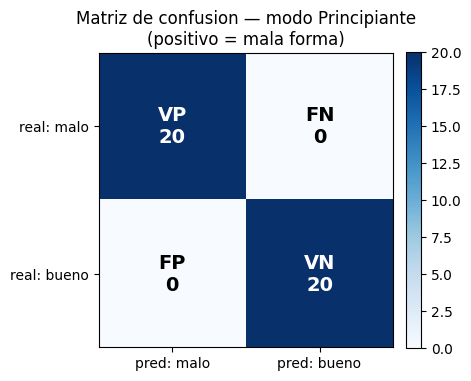

In [5]:
graficar_confusion(res_beginner, "beginner")

### 4.2 Métricas de clasificación

**Qué muestra:** cada barra es una de las métricas definidas en la sección 3, en escala de 0 a 1 (excepto MCC, que puede ser negativa). Más alto es mejor. Permite ver de un vistazo si el modelo falla por *falsas alarmas* (precisión/especificidad bajas) o por *malos no detectados* (sensibilidad baja).

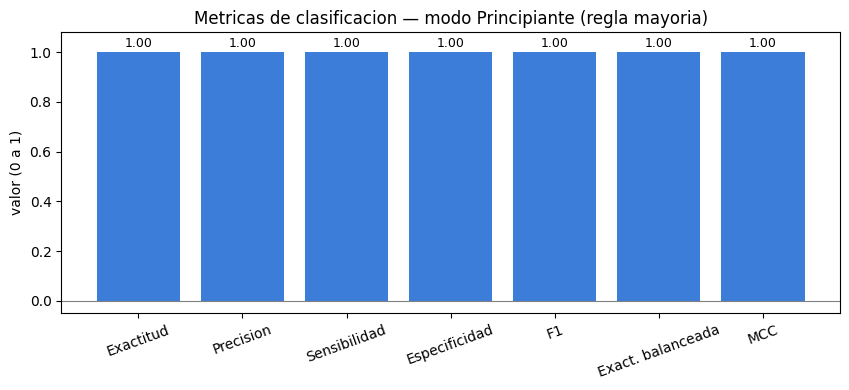

In [6]:
graficar_barras_metricas(res_beginner, "beginner")

### 4.3 Repeticiones detectadas por video

**Qué muestra:** cuántas repeticiones encontró el analizador en cada video (verde = video Bueno, rojo = video Malo). Sirve para verificar la **detección** de repeticiones, que es independiente del veredicto de forma: si una barra está en 0, el analizador no detectó ninguna sentadilla en ese video y no pudo clasificarlo.

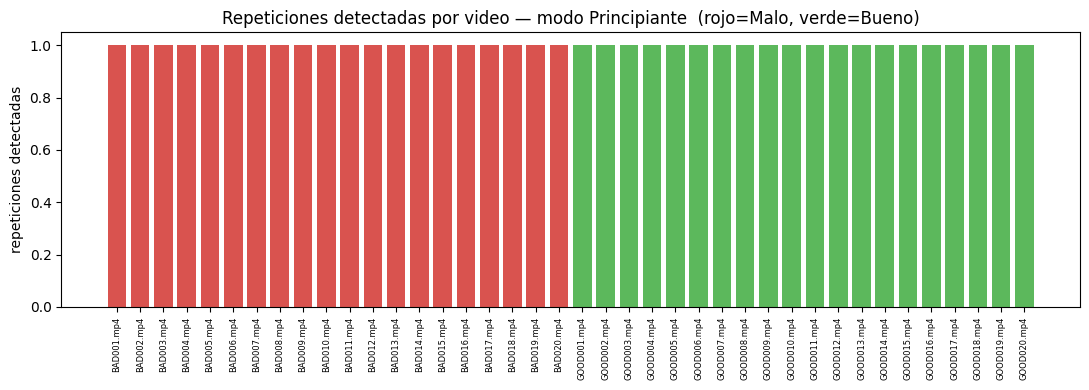

In [7]:
graficar_reps("beginner")

## 5. Resultados — Modo Profesional (`pro`)

Umbrales más estrictos: exige más profundidad de sentadilla, tolera menos avance de la rodilla sobre la punta del pie y menos inclinación del torso. Mismos tres gráficos para comparar.

In [8]:
res_pro = imprimir_resumen("pro")

MODO PROFESIONAL (pro) — regla: mayoria, clase positiva = 'malo'
videos evaluados      : 40  (sin reps detectadas: 0)
--------------------------------------------------------------
Exactitud             : 0.975
Precision (malo)      : 0.952
Sensibilidad (malo)   : 1.000   (malos detectados / todos los malos)
Especificidad (bueno) : 0.950   (buenos respetados / todos los buenos)
F1 (malo)             : 0.976
Exactitud balanceada  : 0.975
MCC                   : 0.951   (+1 perfecto, 0 = azar)
--------------------------------------------------------------
Matriz de confusion   : VP=20  FP=1  VN=19  FN=0


### 5.1 Matriz de confusión

**Qué muestra:** lo mismo que en 4.1, pero para el modo Profesional. Al ser más estricto, este modo tiende a producir más **FP** (falsas alarmas): marca como malas algunas sentadillas buenas que apenas alcanzan la profundidad exigida o que avanzan un poco la rodilla.

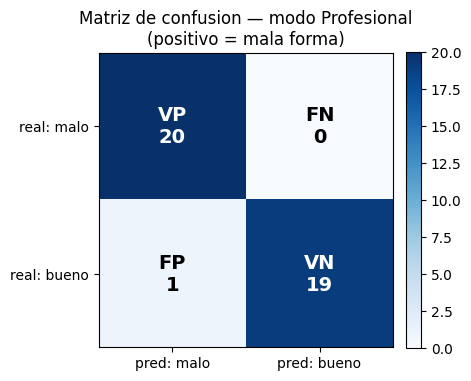

In [9]:
graficar_confusion(res_pro, "pro")

### 5.2 Métricas de clasificación

**Qué muestra:** las mismas métricas para el modo Profesional. Compáralas con las del modo Principiante (sección 4.2): se espera igual o similar **sensibilidad** (detecta los mismos malos) pero **especificidad** algo menor por su mayor rigor.

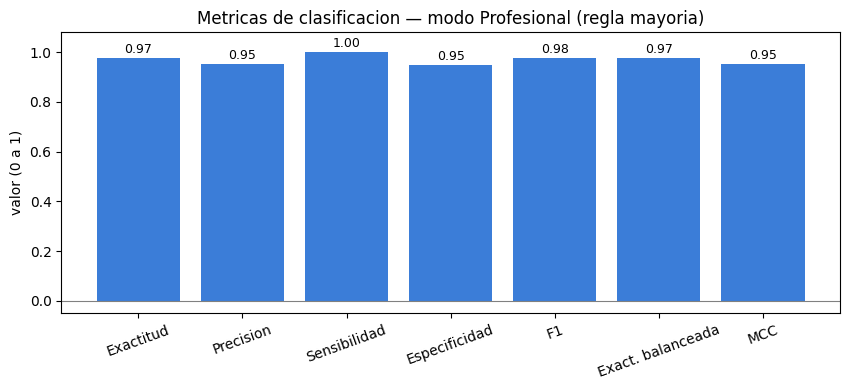

In [10]:
graficar_barras_metricas(res_pro, "pro")

### 5.3 Repeticiones detectadas por video

**Qué muestra:** la detección de repeticiones en modo Profesional. La detección casi no cambia entre modos: los umbrales estrictos afectan al *veredicto de forma*, no a *contar* las repeticiones.

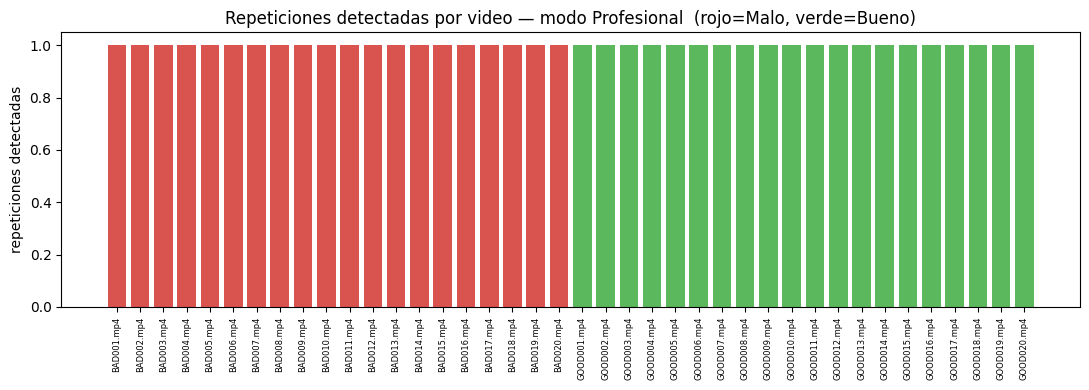

In [11]:
graficar_reps("pro")

## 6. Comparación de modos

Las cuatro combinaciones de `{Principiante, Profesional}` × `{mayoria, estricta}`, para ver el equilibrio entre detectar malos (sensibilidad) y no molestar a los buenos (especificidad) según el rigor elegido.

In [12]:
comparacion = []
for m in MODES:
    sub = subconjunto(m)
    for regla in RULES:
        r = evaluar(sub, f"pred_{regla}")
        comparacion.append({
            "modo": MODO_ES[m], "regla": REGLA_ES[regla],
            "exactitud": r["exactitud"], "precision": r["precision"], "sensibilidad": r["sensibilidad"],
            "especificidad": r["especificidad"], "f1": r["f1"],
            "exact_bal": r["exact_balanceada"], "mcc": r["mcc"],
            "VP": r["vp"], "FP": r["fp"], "VN": r["vn"], "FN": r["fn"], "sin_reps": r["n_sin_reps"],
        })
comp_df = pd.DataFrame(comparacion)
cols_num = ["exactitud", "precision", "sensibilidad", "especificidad", "f1", "exact_bal", "mcc"]
comp_df.style.format({c: "{:.3f}" for c in cols_num}).background_gradient(subset=cols_num, cmap="Greens")

,modo,regla,exactitud,precision,sensibilidad,especificidad,f1,exact_bal,mcc,VP,FP,VN,FN,sin_reps
0,Principiante,mayoria,1.000,1.000,1.000,1.000,1.000,1.000,1.000,20,0,20,0,0
1,Principiante,estricta,1.000,1.000,1.000,1.000,1.000,1.000,1.000,20,0,20,0,0
2,Profesional,mayoria,0.975,0.952,1.000,0.950,0.976,0.975,0.951,20,1,19,0,0
3,Profesional,estricta,0.975,0.952,1.000,0.950,0.976,0.975,0.951,20,1,19,0,0


**Cómo leer la tabla:** cada fila es una configuración; verde más intenso = mejor. La **sensibilidad** dice cuántos malos se detectan; la **especificidad**, cuántos buenos se respetan. La **regla estricta** sube la sensibilidad (condena con una sola repetición marcada) a costa de la especificidad; la **regla mayoria** es más indulgente.

El siguiente gráfico compara las tres métricas clave (sensibilidad, especificidad y F1) entre las cuatro configuraciones.

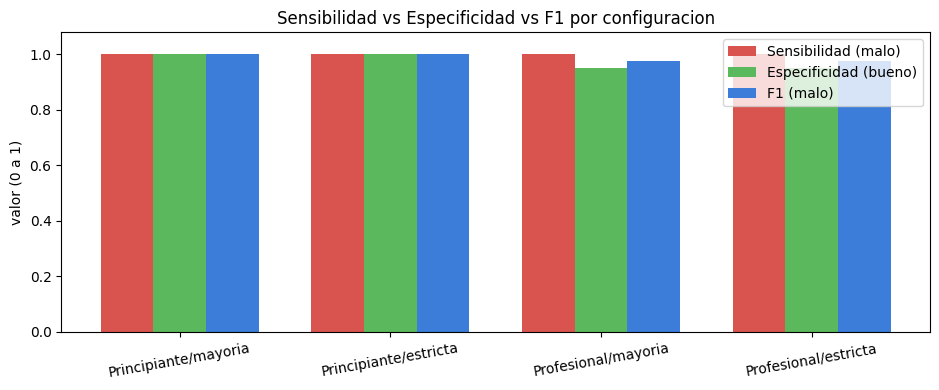

In [13]:
etiquetas = [f"{r.modo}/{r.regla}" for r in comp_df.itertuples()]
x = np.arange(len(etiquetas)); w = 0.25
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.bar(x - w, comp_df["sensibilidad"], w, label="Sensibilidad (malo)", color="#d9534f")
ax.bar(x,     comp_df["especificidad"], w, label="Especificidad (bueno)", color="#5cb85c")
ax.bar(x + w, comp_df["f1"], w, label="F1 (malo)", color="#3b7dd8")
ax.set_xticks(x, etiquetas, rotation=10); ax.set_ylim(0, 1.08); ax.legend()
ax.set_title("Sensibilidad vs Especificidad vs F1 por configuracion")
ax.set_ylabel("valor (0 a 1)"); plt.tight_layout(); plt.show()

## 7. Análisis de errores

Lista de los videos **mal clasificados** en cada modo (regla mayoria), con sus etiquetas de fallo, para poder inspeccionar manualmente por qué fallaron.

In [14]:
def tabla_errores(mode, regla=REGLA_PRINCIPAL):
    col = f"pred_{regla}"
    p = subconjunto(mode)
    err = p[p[col] != p["etiqueta"]].copy()
    if err.empty:
        print(f"Modo {MODO_ES[mode]}: sin errores (clasificacion perfecta).")
        return err
    err["motivo"] = np.where(err[col] == "no_reps", "0 reps detectadas",
                    np.where(err.etiqueta == "bad", "malo no detectado (FN)", "falsa alarma en bueno (FP)"))
    cols = ["archivo", "etiqueta", col, "reps_total", "reps_correctas", "reps_incorrectas", "fallos", "motivo"]
    print(f"Modo {MODO_ES[mode]}: {len(err)} de {len(p)} videos mal clasificados")
    return err[cols].reset_index(drop=True)

display(tabla_errores("beginner"))
display(tabla_errores("pro"))

Modo Principiante: sin errores (clasificacion perfecta).


,archivo,etiqueta,modo,reps_total,reps_correctas,reps_incorrectas,fallos,segundos,pred_majority,pred_all


Modo Profesional: 1 de 40 videos mal clasificados


,archivo,etiqueta,pred_majority,reps_total,reps_correctas,reps_incorrectas,fallos,motivo
0,GOOD011.mp4,good,bad,1,0,1,[lower_hips],falsa alarma en bueno (FP)


### 7.1 Frecuencia de fallos detectados en el conjunto Malo

**Qué muestra:** sobre los 20 videos con mala forma, cuántas veces se disparó cada tipo de fallo (modo Principiante). Indica **qué defectos** está detectando realmente el clasificador. Un fallo que casi nunca aparece sobre los malos no está aportando señal útil.

,tipo_de_fallo,n_videos
0,bend_backwards,20
1,lower_hips,20
2,knee_over_toe,2


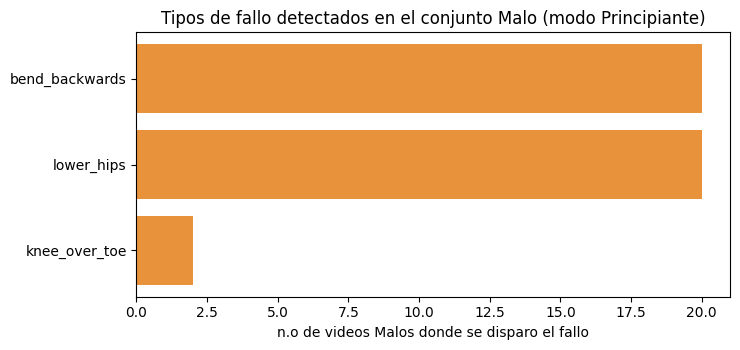

In [15]:
malos = subconjunto("beginner")
malos = malos[malos["etiqueta"] == "bad"]
conteo = Counter(t for fallos in malos["fallos"] for t in fallos)
if conteo:
    tdf = pd.DataFrame(sorted(conteo.items(), key=lambda kv: -kv[1]), columns=["tipo_de_fallo", "n_videos"])
    display(tdf)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    ax.barh(tdf["tipo_de_fallo"][::-1], tdf["n_videos"][::-1], color="#e8923b")
    ax.set_xlabel("n.o de videos Malos donde se disparo el fallo")
    ax.set_title("Tipos de fallo detectados en el conjunto Malo (modo Principiante)")
    plt.tight_layout(); plt.show()
else:
    print("No se registraron etiquetas de fallo en el conjunto Malo.")

## 8. Detalle por video y rendimiento

Tabla completa por video (modo Principiante) y tiempo de procesamiento.

In [16]:
detalle = subconjunto("beginner")[["archivo", "etiqueta", "reps_total", "reps_correctas", "reps_incorrectas",
                                    "pred_majority", "pred_all", "fallos", "segundos"]] \
            .sort_values(["etiqueta", "archivo"]).reset_index(drop=True)
p_beg = subconjunto("beginner")
print(f"Tiempo medio por video (Principiante): {p_beg['segundos'].mean():.2f}s "
      f"(total {p_beg['segundos'].sum():.1f}s para {len(p_beg)} videos)")
detalle

Tiempo medio por video (Principiante): 3.05s (total 122.1s para 40 videos)


,archivo,etiqueta,reps_total,reps_correctas,reps_incorrectas,pred_majority,pred_all,fallos,segundos
0,BAD001.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",2.65
1,BAD002.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",3.43
2,BAD003.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",3.68
3,BAD004.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",3.09
4,BAD005.mp4,bad,1,0,1,bad,bad,"[bend_backwards, knee_over_toe, lower_hips]",2.72
5,BAD006.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",2.83
6,BAD007.mp4,bad,1,0,1,bad,bad,"[bend_backwards, knee_over_toe, lower_hips]",3.00
7,BAD008.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",2.61
8,BAD009.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",3.06
9,BAD010.mp4,bad,1,0,1,bad,bad,"[bend_backwards, lower_hips]",2.32


## 9. Resumen final

In [17]:
print("RESUMEN")
print("=" * 64)
print(f"Conjunto: {subconjunto('beginner')['etiqueta'].value_counts().to_dict()}  "
      f"({subconjunto('beginner')['archivo'].nunique()} videos)\n")
for mode, res in (("beginner", res_beginner), ("pro", res_pro)):
    print(f"Modo {MODO_ES[mode]:<12}: exactitud={res['exactitud']:.3f}  F1={res['f1']:.3f}  "
          f"sensibilidad={res['sensibilidad']:.3f}  especificidad={res['especificidad']:.3f}  MCC={res['mcc']:.3f}")
    print(f"               matriz: VP={res['vp']} FP={res['fp']} VN={res['vn']} FN={res['fn']}")
print("\nNota: 'malo' = clase positiva. La sensibilidad es la cifra clave de seguridad")
print("(que fraccion de las sentadillas con mala forma se detecta).")

RESUMEN
Conjunto: {'bad': 20, 'good': 20}  (40 videos)

Modo Principiante: exactitud=1.000  F1=1.000  sensibilidad=1.000  especificidad=1.000  MCC=1.000
               matriz: VP=20 FP=0 VN=20 FN=0
Modo Profesional : exactitud=0.975  F1=0.976  sensibilidad=1.000  especificidad=0.950  MCC=0.951
               matriz: VP=20 FP=1 VN=19 FN=0

Nota: 'malo' = clase positiva. La sensibilidad es la cifra clave de seguridad
(que fraccion de las sentadillas con mala forma se detecta).
